In [ ]:
# Run from the repository root so that relative paths (data/..., outputs-model-D/...) resolve.
# Jupyter starts in the notebook's own folder (paper/), so step up once.
import os
if os.path.basename(os.getcwd()) == "paper":
    os.chdir("..")
print("Working directory:", os.getcwd())

In [1]:
import csv
from scipy.stats import multivariate_normal
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
#import wandb
import os
from tqdm.notebook import tqdm
import copy
from ViT_rectangle import *
from ViT_sampling_rectangle import *
from training_rectangle import *
#from sampling import *
from tqdm import tqdm  # For progress bars
import time
from IPython.display import display, Image
from PIL import Image as PILImage
import io

In [ ]:
# Rebuild the vocabulary (must match training data setup)
npz = np.load("data/mrf_dataset_D.npz")
imgs = npz["images"]
train_tensor = torch.tensor(imgs, dtype=torch.float32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load("outputs-model-D/vocab_checkpoint.pt")

vocab = checkpoint["vocab"]
counts = checkpoint["counts"]

# rewrap mask token
mask_token = torch.tensor([0.5000, 0.5000, 0.5000, 0.5000], requires_grad=True)

patch_size = checkpoint["patch_size"]
cap_size = checkpoint["cap_size"]

nx, ny = train_tensor.shape[1:]
num_patches = (nx // patch_size) * (ny // patch_size)
patch_dim   = patch_size * patch_size

# Recreate model with same dims as before
model = StackedContextViT(
    vocab=vocab,
    mask_token=mask_token,
    patch_dim=patch_dim,
    num_patches=num_patches,
    grid_size = (6,12),
    emb_dim=64,
    num_heads=2,
    num_layers=2,
    ffn_dim=256,
    use_pos_emb=True,
    pos_emb_init=None,
    use_rel_bias=True,
    rel_bias_init=None
)

# Load weights
model.load_state_dict(torch.load("outputs-model-D/model_epoch_1000.pth", map_location="cpu"))
model.eval()

In [4]:
def show_grid(data, scale=4, nrow=3, ncol=3, spacing=2, seed=None, indices=None):
    """
    Display a grid of images from a NumPy array or PyTorch tensor.

    Args:
        data: NumPy array (N,H,W) or torch.Tensor (N,H,W) or (N,1,H,W)
        scale: upscaling factor for display size
        nrow, ncol: grid dimensions
        spacing: number of pixels between images in the grid
        seed: random seed for reproducibility
        indices: list/array of indices to use (overrides random sampling)
    """
    # Convert torch → numpy
    if isinstance(data, torch.Tensor):
        arr = data.detach().cpu().numpy()
    else:
        arr = np.array(data)

    # Squeeze if channel dim present
    if arr.ndim == 4 and arr.shape[1] == 1:
        arr = arr[:,0]

    N, H, W = arr.shape
    total = nrow * ncol

    # Pick indices
    if indices is not None:
        idxs = np.array(indices)[:total]
    else:
        rng = np.random.default_rng(seed)
        idxs = rng.choice(N, total, replace=False)

    # Prepare grid canvas with white background
    grid_h = nrow * H + (nrow - 1) * spacing
    grid_w = ncol * W + (ncol - 1) * spacing
    grid = np.full((grid_h, grid_w), 255, dtype=np.uint8)  # white background

    for k, idx in enumerate(idxs):
        img = arr[idx]
        # scale to 0-255 if binary {0,1} or float
        if img.dtype != np.uint8 or img.max() <= 1:
            img = (img * 255).astype(np.uint8)
        r, c = divmod(k, ncol)
        y0, x0 = r*(H+spacing), c*(W+spacing)
        grid[y0:y0+H, x0:x0+W] = img

    # Convert to PIL image and upscale
    out = PILImage.fromarray(grid)
    out = out.resize((grid_w*scale, grid_h*scale), PILImage.NEAREST)
    display(out)

In [5]:
model.eval()
gen_imgs, cum_ll, _ = generate_images_batch(  # returns (images, log q(x|y), log p(x))
    model,
    patch_size      = 2,
    image_size      = (12,24),
    batch_size      = 1000,      # how many to sample now
    device          = device,
    condition_indices = None,  # unconditional
    condition_values  = None,
    generation_order  = "raster",   # try "random" too
    temperature       = 1.0         # try 0.9 / 0.8 for sharper
)

gen_imgs.shape, cum_ll.shape

(torch.Size([1000, 12, 24]), (1000, 72))


ViT-generated images:



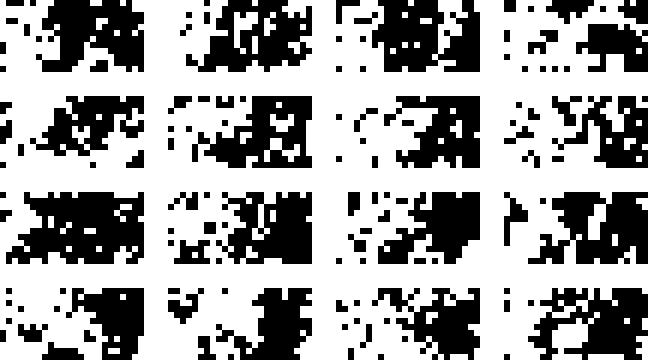


---------------------------------------------------------------------------------

MRFs:



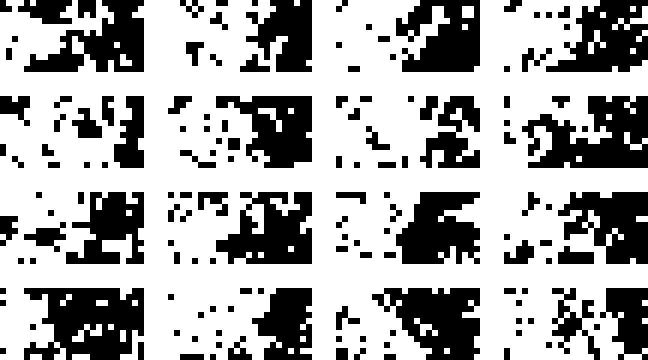

In [6]:
print("\nViT-generated images:\n")
show_grid(gen_imgs, scale=6, nrow=4, ncol=4, spacing = 4, seed=123)
print("\n---------------------------------------------------------------------------------")
print("\nMRFs:\n")
show_grid(imgs, scale=6, nrow=4, ncol=4, spacing = 4, seed = 123)

In [ ]:
np.savez_compressed("data/ViT-model-D.npz", images=(gen_imgs.numpy()).astype(np.uint8))